# Phase II – What did TiRex-2 learn?

We open the black box of TiRex-2 on the TIME benchmark (short term) and test the failure modes we found in Phase I.
The concept and hypotheses are in [ai-interactions/phase2.md](ai-interactions/phase2.md); the code lives in [phase2/](phase2/).

**Approach.** We take the Phase I behaviours, define *failing* and *successful* groups of forecast windows, and compare them
**within the same dataset** (Phase I showed that pooled effects are mostly dataset differences). For every hypothesis we combine
an **attribution** view (Integrated Gradients, LIME, KernelSHAP, STL-component Shapley), a **representation** view (hidden states,
linear probes, kNN, mLSTM gate memory) and a **counterfactual** test.

Long-running results are cached in `output/phase2/`; regenerate them with `uv run python -m phase2 attributions`
(≈ 1.5 h on an RTX 3070) or by passing `force=True`.

In [20]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sys

sys.path.append("./team_blue")
sys.path.append("./team_blue/phase2")
from phase2 import analysis as AN
from phase2 import counterfactual as C
from phase2 import groups as G
from phase2 import model_io as M
from phase2 import pipeline as P
from phase2 import plots as PL
from phase2 import representations as R
from phase2 import windows as W

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [21]:
from phase2 import CACHE_DIR

CACHE_DIR

PosixPath('/home/noah/aiviz/output/phase2')

## 1. The model from the inside – what can we look at?

* **Input**: a rule-based *PostProcessor* first checks for a linear trend (OLS on the z-scored context, `|slope|·len ≥ 1.5` and `R² ≥ 0.87`);
  if it fires, the series is first-differenced (`tta_diff`). Then instance standardisation + `arcsinh`, patches of 32 steps.
  The network sees exactly the **last 2048 steps = 64 context tokens**, followed by 10 NaN future tokens.
* **Stack**: 12 blocks alternating **mLSTM / sLSTM** time mixers. The variate-mixer attention has a single token per group for
  univariate data, so **attention maps carry no information here**; we use hidden states, gates and gradients instead.
* The **last context token (index 63)** emits the first forecast patch; for horizons ≤ 32 it is the *only* token that matters.
* NaN is a first-class "missing" signal (explicit mask channel), so masking a context segment with NaN is an in-distribution
  perturbation for LIME/SHAP – no artificial zero baseline.

Engineering notes: the Triton mLSTM kernels do not compile with the installed Triton, so the model is built with the native PyTorch
kernels and moved to the GPU. `Scaler.scale` is replaced by a numerically identical version whose gradients are NaN-free
(the original back-propagates `NaN·0` through the padding). The check below confirms we reproduce the stored Phase I forecasts.

In [22]:
wc = W.load_window_cube("short")
check = []
for r in wc.sample(20, random_state=1).itertuples():
    w = W.get_window(r)
    f = M.forecast([w.context], len(w.truth))[0]
    check.append(np.abs(f - w.stored).max() / (np.abs(w.stored).max() + 1e-9))
print(
    f"max relative deviation from the Phase I predictions over 20 windows: {max(check):.1e}"
)

max relative deviation from the Phase I predictions over 20 windows: 4.5e-04


## 2. Behaviour groups (from Phase I)

| contrast | fail group | ok group | Phase I finding |
|---|---|---|---|
| `trend` | trend strength ≥ q90, seasonal < 0.5, MASE > 1.1 | same features, MASE < 0.7 | F4a/F7: flat at last value while truth drifts, F5 mean reversion |
| `switch` | trend strength ≤ q10, MASE > 1.1, flat forecast | seasonal strength ≥ 0.8, MASE < 0.7 | F4b/F6: level switching → flat in the middle |
| `acf` | residual ACF1 < 0 | ACF1 > 0.5 | F1: negative ACF1 → higher error |
| `calib` | 80 % interval covers ≤ 20 % of truth, MASE > 1.2 | coverage ≥ 80 %, MASE < 0.7 | F8: over-confidence |

Sampling: ≤ 100 windows per group, one window per series, ≤ 15 per dataset, datasets present on both sides of a contrast first.

In [23]:
behaviour = G.build_behaviour_table("short")
sample = P.load_sample()
print(
    f"{len(behaviour)} short-term windows, {sample.uid.nunique()} unique windows in the analysis sample"
)
sample.groupby(["contrast", "group"]).agg(
    n=("uid", "size"),
    datasets=("dataset", "nunique"),
    median_MASE=("MASE", "median"),
    median_flat_ratio=("flat_ratio", "median"),
    median_coverage=("coverage80", "median"),
).round(2)

95633 short-term windows, 744 unique windows in the analysis sample


n  datasets  median_MASE  median_flat_ratio  median_coverage
contrast group                                                                      
acf      negacf       100        10         0.61               0.34             0.85
         posacf       100        11         0.46               0.70             0.88
calib    calibrated   100        14         0.35               0.37             0.94
         overconf     100        19         1.99               0.34             0.06
switch   season_ok    100        15         0.38               0.89             0.93
         switch_fail   50         7         1.28               0.06             0.76
trend    trend_fail   100        16         1.53               0.20             0.50
         trend_ok     100        12         0.38               0.13             1.00

## 3. Step 0 – Is the rule-based differencing (`tta_diff`) responsible?

Before attributing failures to the learned network, we check whether the hand-crafted trend rule is involved.

trend rule fires on 1.6% of all short windows (1554)
share flagged per group: {'calibrated': 0.02, 'negacf': 0.0, 'overconf': 0.06, 'posacf': 0.02, 'season_ok': 0.0, 'switch_fail': 0.0, 'trend_fail': 0.02, 'trend_ok': 0.02}
{'MASE_on': 0.429, 'MASE_off': 0.43, 'width_on': 1.323, 'width_off': 1.734} - better without differencing: 56%


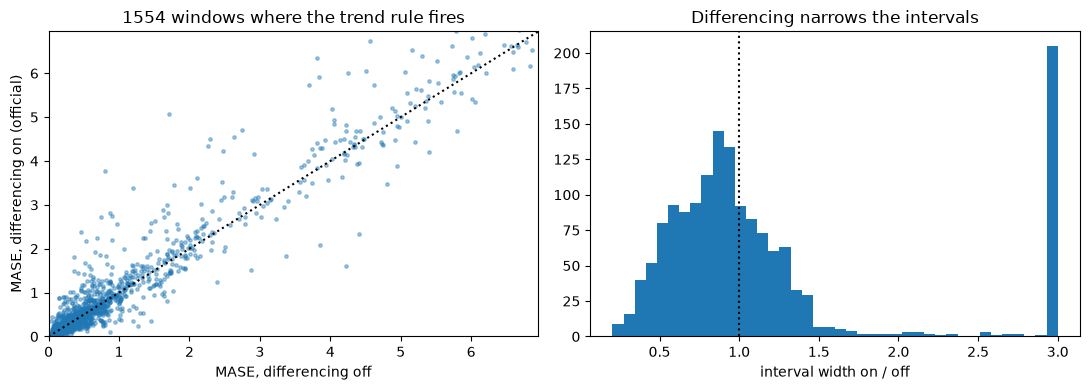

In [24]:
flagged = P.flagged_population_check()
print(
    f"trend rule fires on {behaviour.trend_flag.mean():.1%} of all short windows ({behaviour.trend_flag.sum()})"
)
print(
    "share flagged per group:",
    sample.groupby("group").trend_flag.mean().round(3).to_dict(),
)
print(
    flagged[["MASE_on", "MASE_off", "width_on", "width_off"]]
    .median()
    .round(3)
    .to_dict(),
    f"- better without differencing: {(flagged.MASE_off < flagged.MASE_on).mean():.0%}",
)
PL.tta_diff_plot(flagged)
plt.show()

**Result.** The rule fires on only 1.6 % of the windows (mostly Coastal_T_S, Water_Quality_Darwin, current_velocity, US_Term_Structure).
Where it fires, the median MASE is unchanged (0.429 vs 0.430) while the intervals become ~24 % narrower. The failure groups are
not dominated by the rule (≤ 6 % flagged), so **the failures are produced by the learned network** and all following analyses use the
official setting.

### What distinguishes the groups at the output? (direction of history, forecast and truth)
`hist_slope`, `fc_slope`, `truth_slope` are OLS slopes × H in MASE-scale units; `level_gap` = first forecast step − last observation.

In [25]:
AN.direction_table(sample).round(2)

,forecast_reverts,truth_continues,abs_hist_slope,abs_fc_slope,abs_truth_slope,abs_level_gap
group,,,,,,
calibrated,0.57,0.47,0.06,0.19,0.49,0.13
negacf,0.53,0.43,0.04,0.18,0.31,0.31
overconf,0.62,0.43,0.15,0.39,2.65,0.14
posacf,0.50,0.50,0.17,1.03,1.12,0.09
season_ok,0.61,0.46,0.15,0.95,0.79,0.21
switch_fail,0.58,0.48,0.12,0.07,0.74,0.93
trend_fail,0.51,0.59,0.36,0.30,2.24,0.11
trend_ok,0.50,0.51,0.17,0.10,0.45,0.06


RESULT_DIRECTION

## 4. H1 – Where in the context does the model look? (attribution)

*Hypothesis:* failing windows rely almost exclusively on the most recent patches, successful (seasonal) windows also use older lags.

Explanation targets (scale-free, divided by the MASE scale): **level** (mean median forecast − last value), **slope** of the median
forecast, **width** of the 80 % interval and **error** (MAE vs. truth). Three techniques over 64 lag segments of 32 steps:
Integrated Gradients (gradient view, flat mean baseline – exact thanks to the model's affine equivariance, completeness holds),
LIME and KernelSHAP (perturbation view, segments masked with NaN).

attributions available for 744 / 744 windows


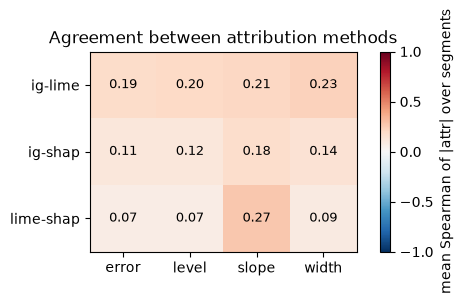

In [26]:
attrs = P.load_attributions(sample)
print(f"attributions available for {len(attrs)} / {sample.uid.nunique()} windows")
summary = AN.attribution_summary(sample, attrs)
agree = AN.method_agreement(attrs)
PL.method_agreement_plot(agree)
plt.show()

In [27]:
# agreement on *which windows* look at the recent past (recency4 = |attr| share of the last 4 segments)
AN.recency_agreement(summary).pivot(
    index="pair", columns="target", values="mean"
).round(2)

target,error,level,slope,width
pair,,,,
ig-lime,0.39,0.36,0.46,0.37
ig-shap,0.40,0.31,0.38,0.33
lime-shap,0.27,0.32,0.70,0.36


**Do the techniques agree?** RESULT_AGREEMENT

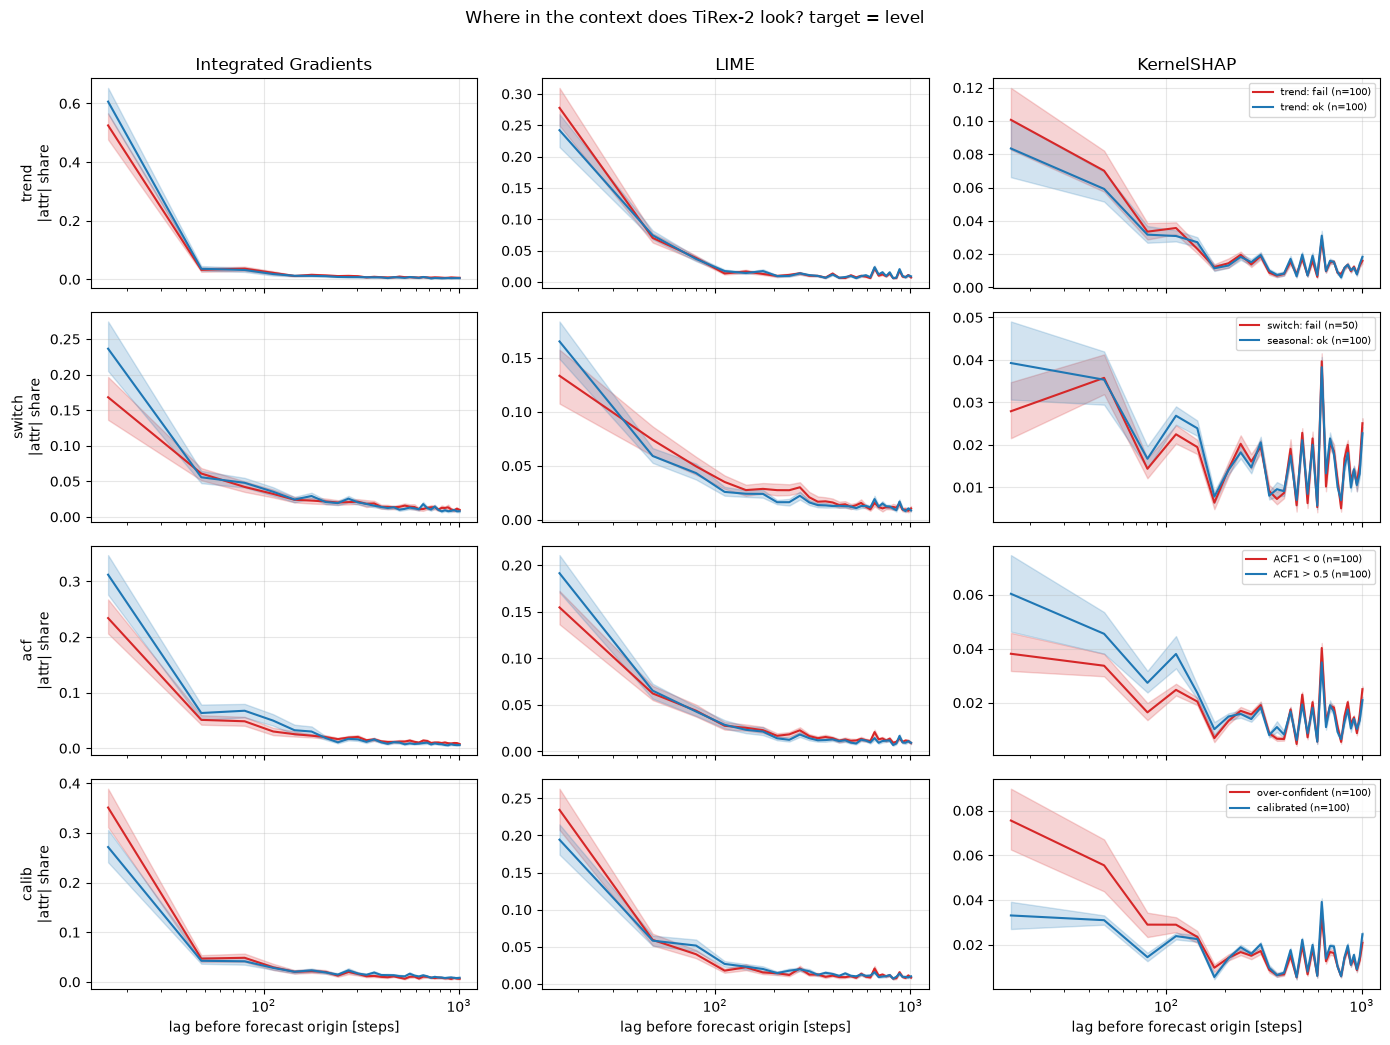

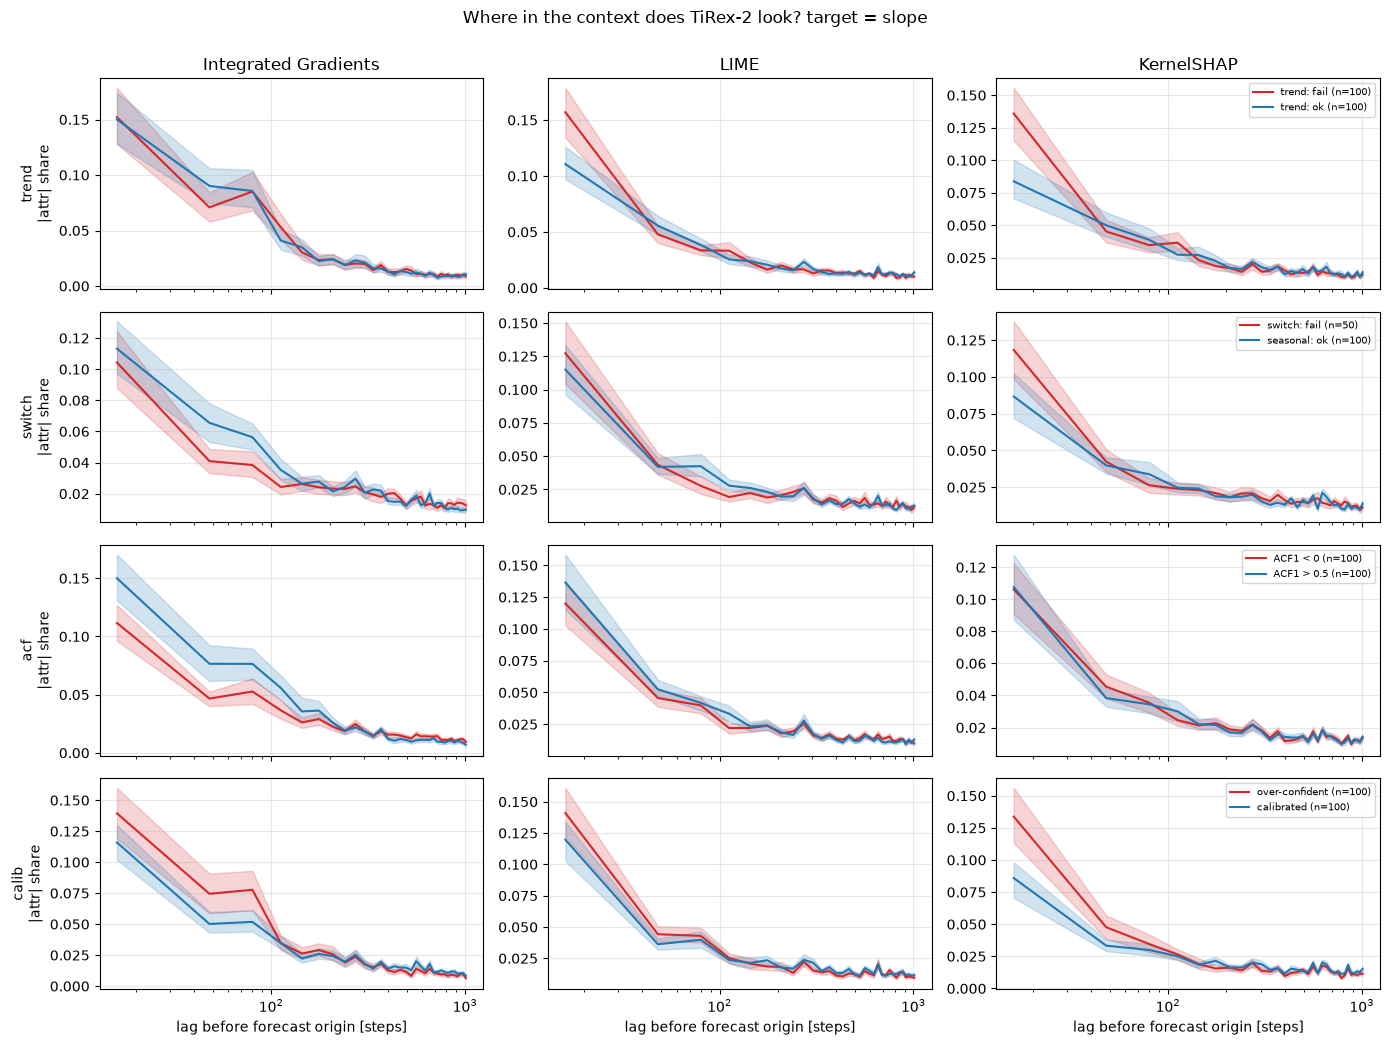

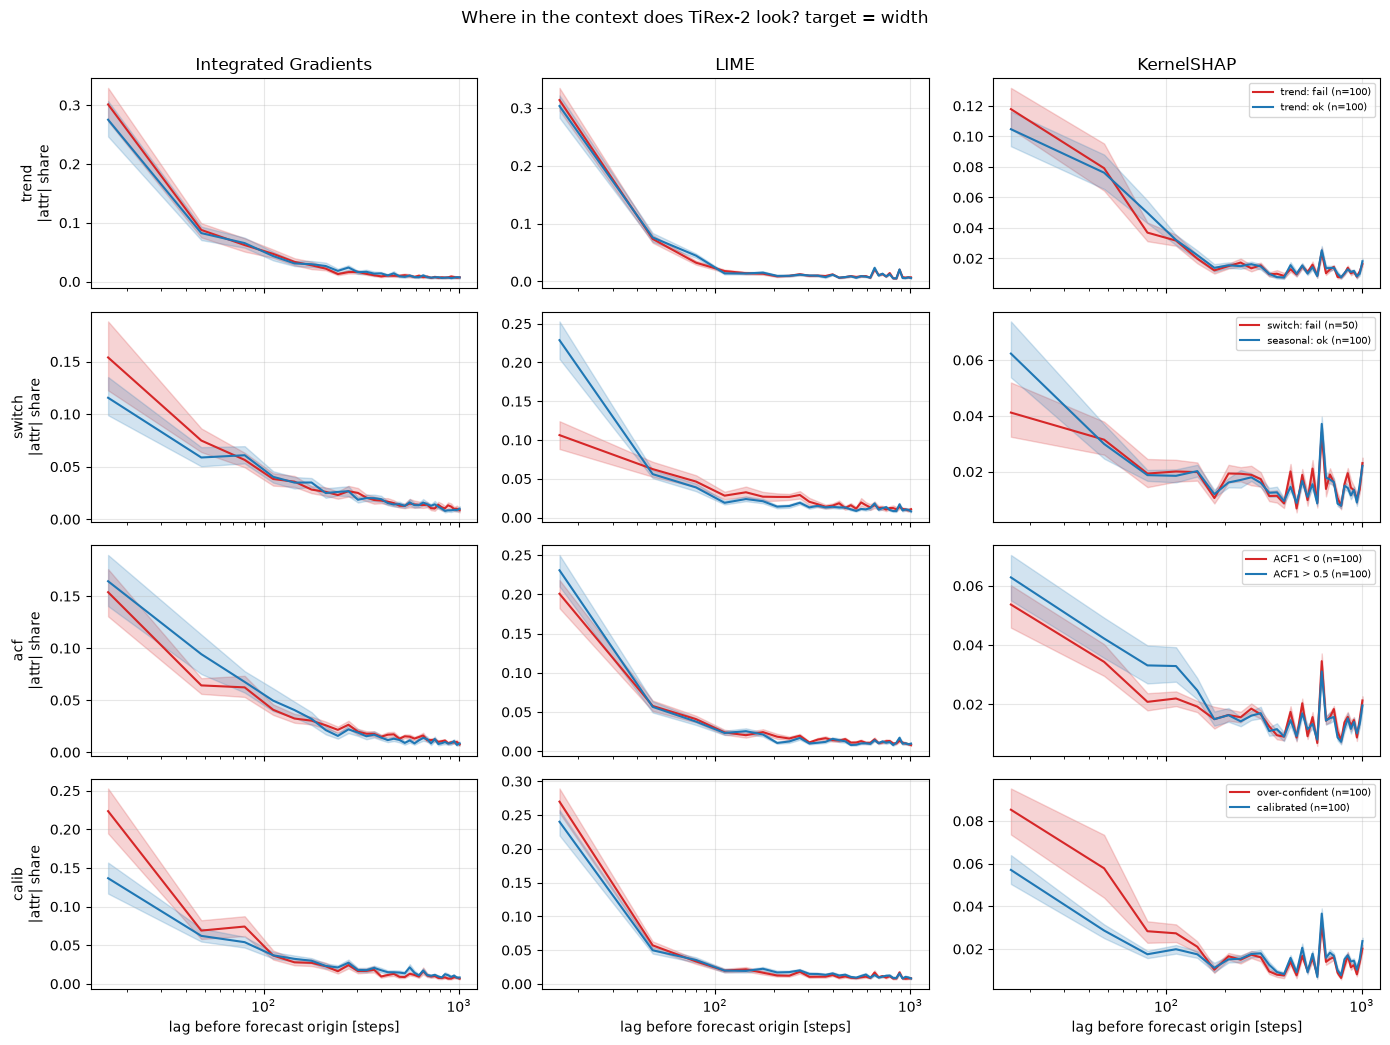

In [28]:
for target in ["level", "slope", "width"]:
    PL.lag_profile_grid(sample, attrs, target)
    plt.show()

In [29]:
tests = AN.within_dataset_test(summary, "recency4")
tests.pivot_table(
    index=["contrast", "target"],
    columns="method",
    values=["median_diff", "share_fail_higher", "p_wilcoxon"],
).round(3)

median_diff               p_wilcoxon               share_fail_higher              
method                   ig   lime   shap         ig   lime   shap                ig   lime   shap
contrast target                                                                                   
acf      error       -0.070  0.032 -0.001      0.131  0.492  0.846             0.200  0.600  0.500
         level       -0.112 -0.010 -0.005      0.064  0.492  0.160             0.300  0.500  0.300
         slope       -0.063  0.016  0.026      0.049  0.770  0.375             0.100  0.500  0.700
         width       -0.006  0.019 -0.019      1.000  0.770  0.037             0.500  0.600  0.200
calib    error       -0.038  0.036  0.006      0.266  0.301  0.622             0.333  0.750  0.583
         level       -0.026 -0.022  0.004      0.970  0.622  0.970             0.417  0.417  0.500
         slope       -0.076 -0.019 -0.009      0.077  0.339  0.910             0.333  0.500  0.500
         width        0.007  0.011  0.004      0.850  0.569  0.569             0.583  0.583  0.500
switch   error       -0.149 -0.010  0.000      0.062  1.000  1.000             0.000  0.400  0.600
         level        0.055  0.085  0.000      0.812  0.812  1.000             0.600  0.600  0.600
         slope       -0.035  0.047  0.026      0.625  1.000  1.000             0.200  0.600  0.600
         width        0.146 -0.145  0.013      0.188  0.188  0.438             0.800  0.200  0.600
trend    error       -0.106  0.004  0.005      0.002  0.519  0.470             0.167  0.500  0.667
         level       -0.084  0.048  0.019      0.002  0.034  0.204             0.167  0.750  0.750
         slope        0.030  0.061  0.052      0.204  0.027  0.003             0.667  0.750  0.833
         width        0.039 -0.031  0.003      0.052  0.519  0.677             0.833  0.333  0.500

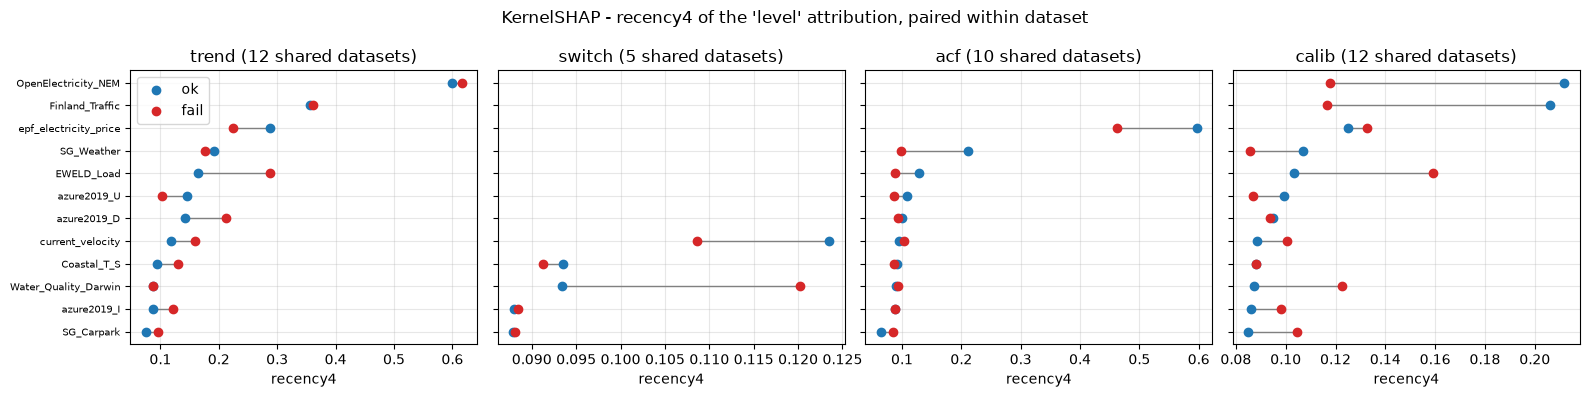

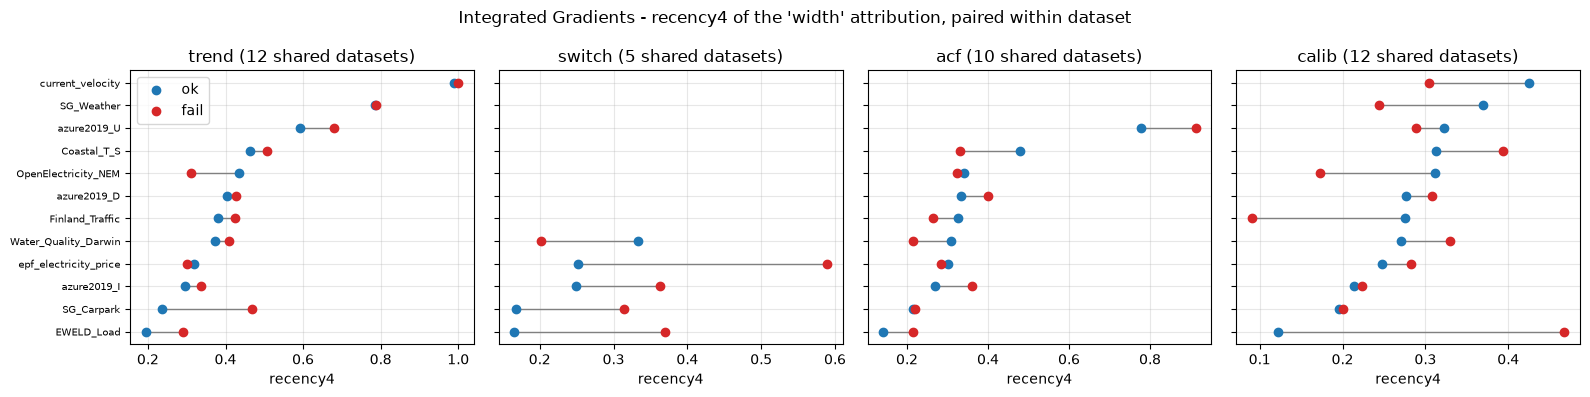

In [30]:
PL.recency_by_dataset(summary, method="shap", target="level")
plt.show()
PL.recency_by_dataset(summary, method="ig", target="width")
plt.show()

### Matched examples (same dataset, fail vs ok)

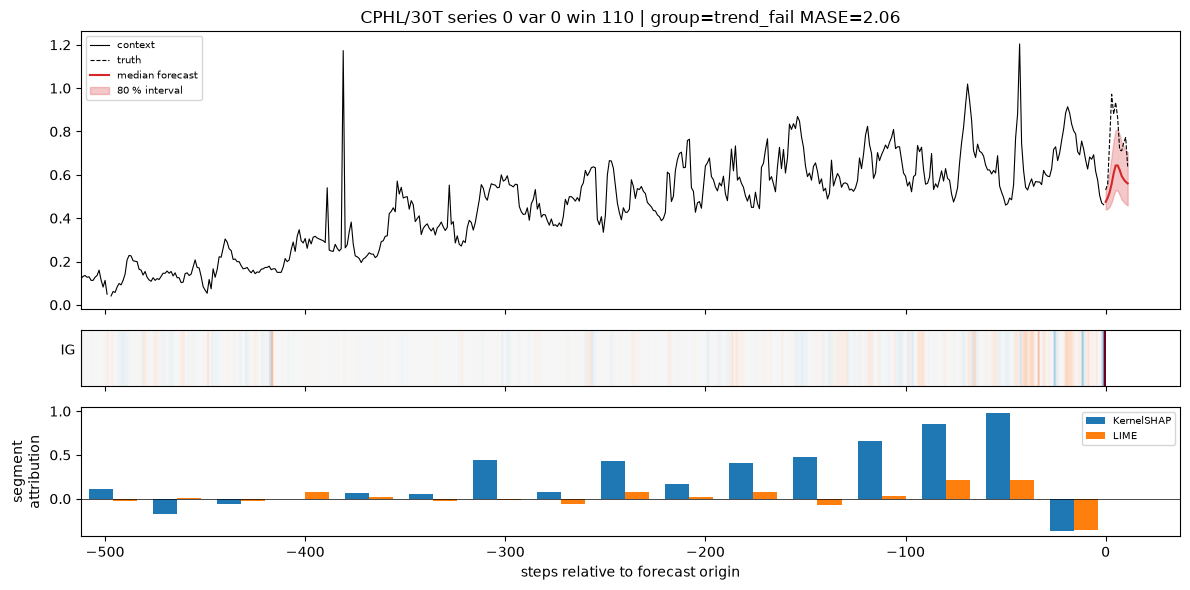

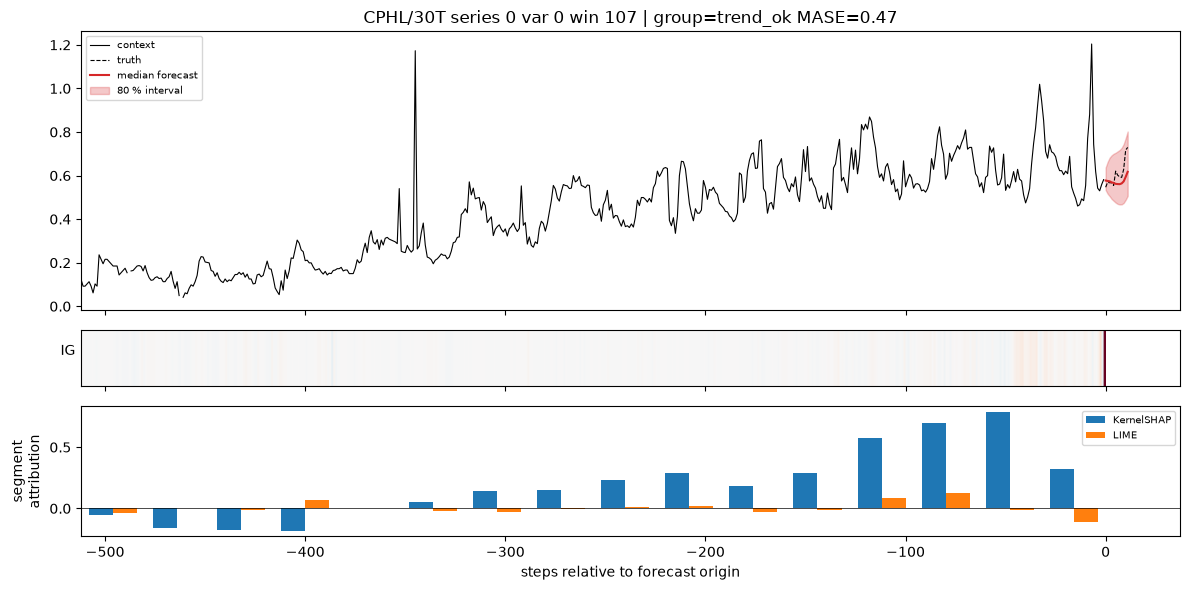

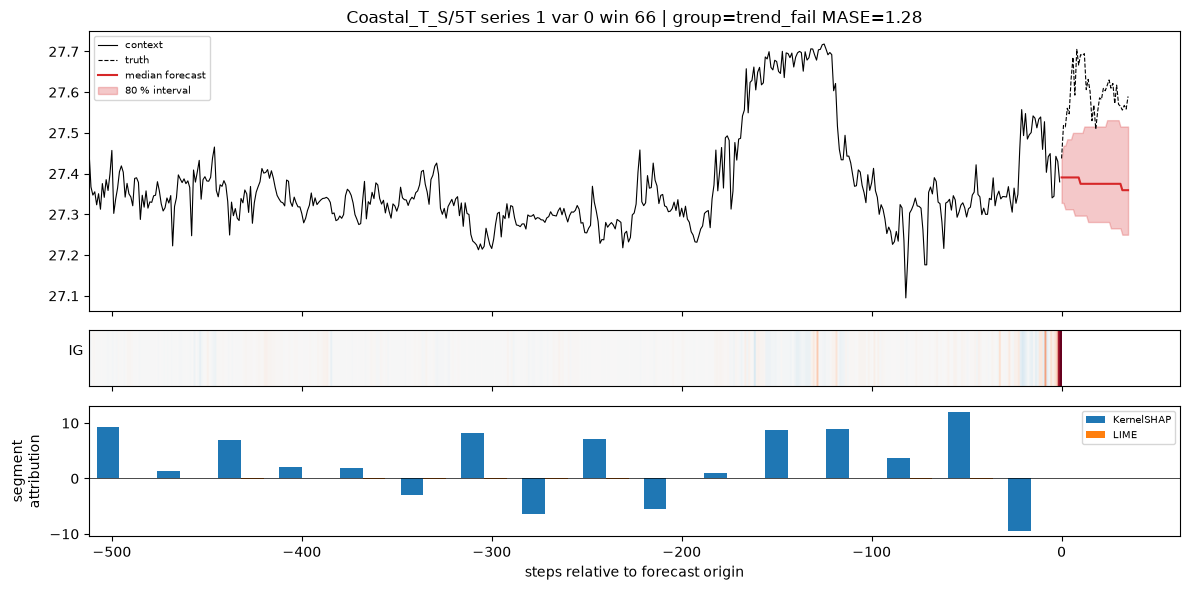

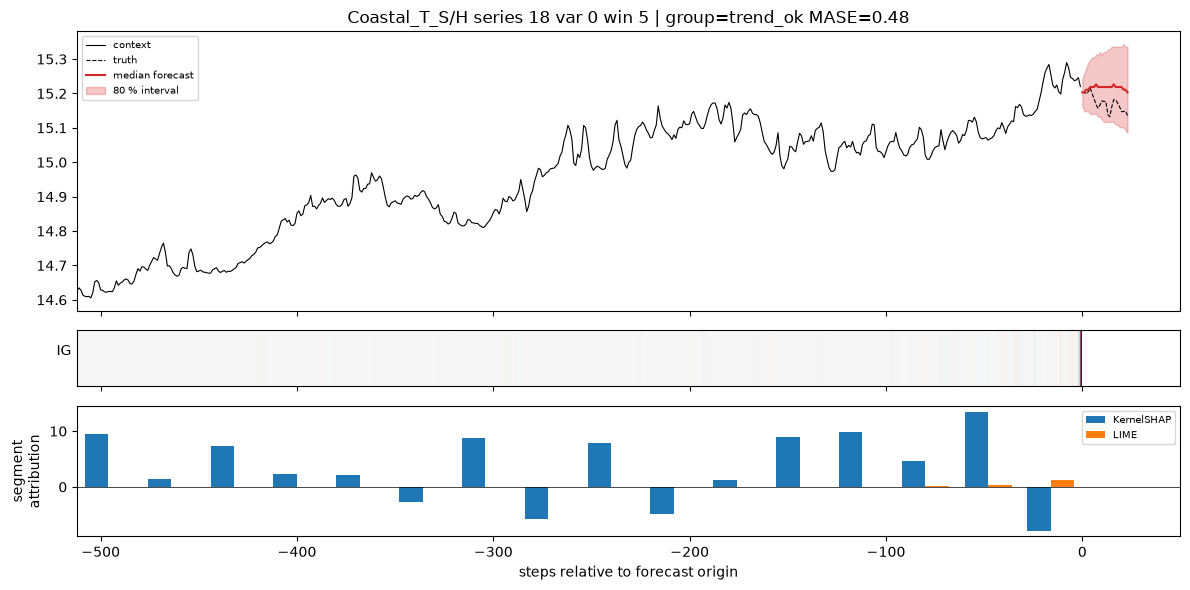

In [31]:
def matched_examples(contrast, n=2, seed=0):
    s = sample[sample.contrast == contrast]
    s = s[s.uid.isin(attrs)]
    shared = set(s[s.side == "fail"].dataset) & set(s[s.side == "ok"].dataset)
    ds = sorted(shared)[:n]
    for d in ds:
        for side in ["fail", "ok"]:
            r = s[(s.dataset == d) & (s.side == side)].sample(1, random_state=seed)
            plt.show(PL.window_strip(next(r.itertuples()), attrs))


matched_examples("trend")

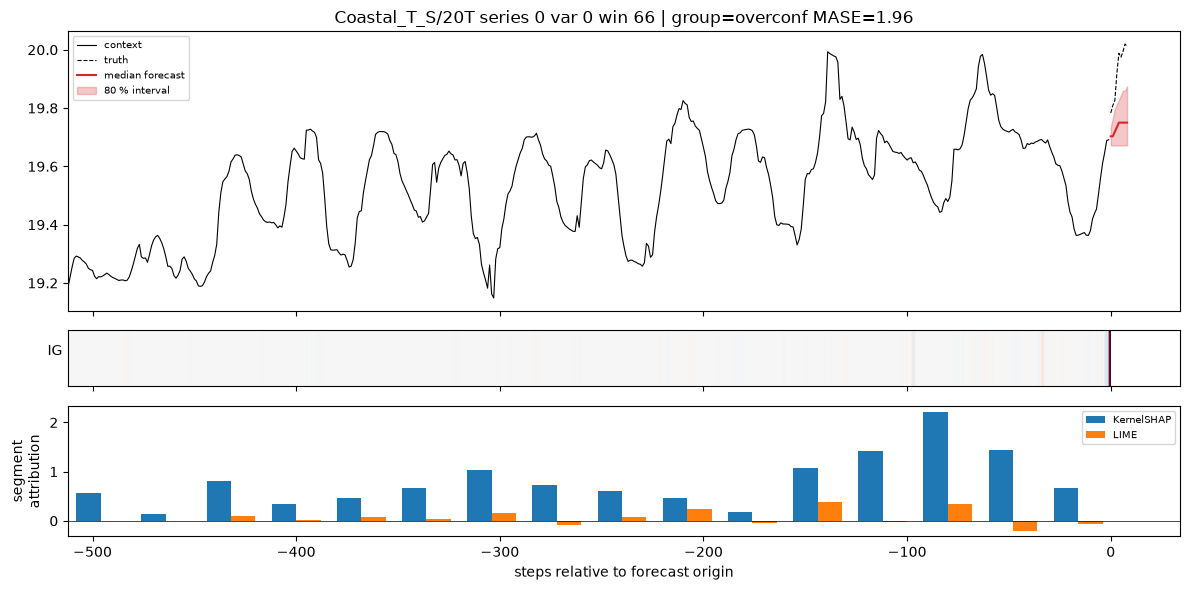

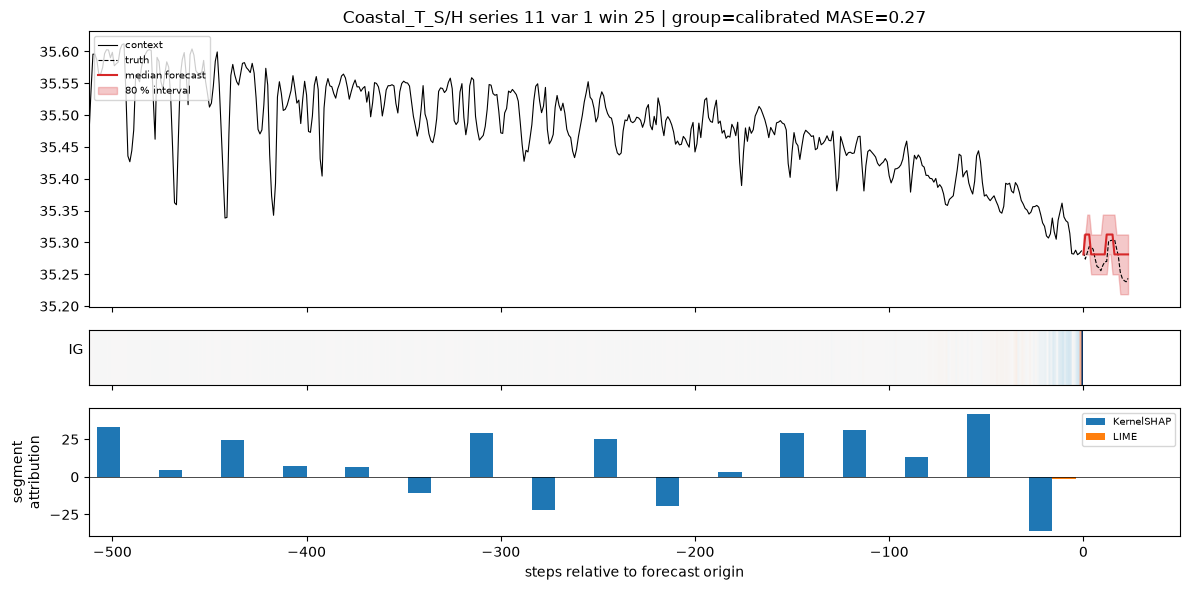

In [32]:
matched_examples("calib", n=1)

## 5. H1 (representation side) – mLSTM gate memory

For an mLSTM the contribution of patch *s* to the memory read at the last context token is exactly
`exp(i_s + Σ_{s<k≤t} log σ(f_k))` (normalised). This is a *mechanistic* memory profile, independent of attribution methods.

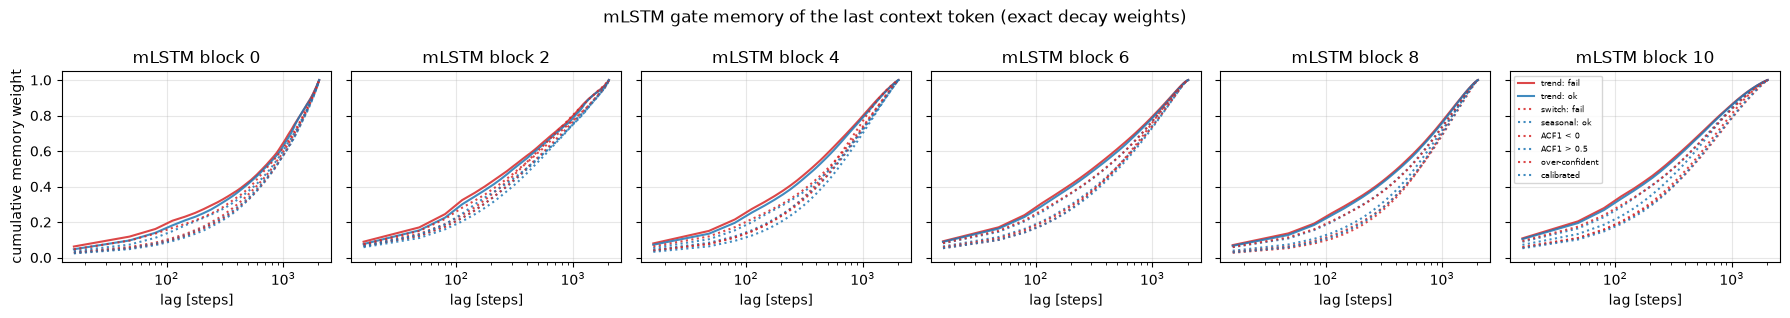

,mlstm_0,mlstm_2,mlstm_4,mlstm_6,mlstm_8,mlstm_10
group,,,,,,
calibrated,0.093,0.204,0.124,0.179,0.115,0.189
negacf,0.100,0.223,0.148,0.196,0.122,0.198
overconf,0.167,0.281,0.217,0.265,0.204,0.295
posacf,0.149,0.247,0.199,0.255,0.199,0.284
season_ok,0.103,0.223,0.154,0.202,0.137,0.232
switch_fail,0.110,0.240,0.148,0.181,0.105,0.202
trend_fail,0.208,0.324,0.274,0.305,0.248,0.344
trend_ok,0.181,0.300,0.254,0.290,0.237,0.331


In [33]:
table, rep = R.extract(sample)
PL.memory_plot(table, rep, sample)
plt.show()
mem = AN.memory_table(table, rep, sample)
mem.groupby("group")[[c for c in mem.columns if c.startswith("mlstm")]].mean().round(3)

## 6. H2 – Which signal component drives the forecast? (STL-component Shapley)

The context is decomposed with STL into level + trend + seasonal + residual. Players = {trend, seasonal, residual} (level always
present); a missing player is replaced by zero. 3 players → exact Shapley values from 8 forward passes per window.

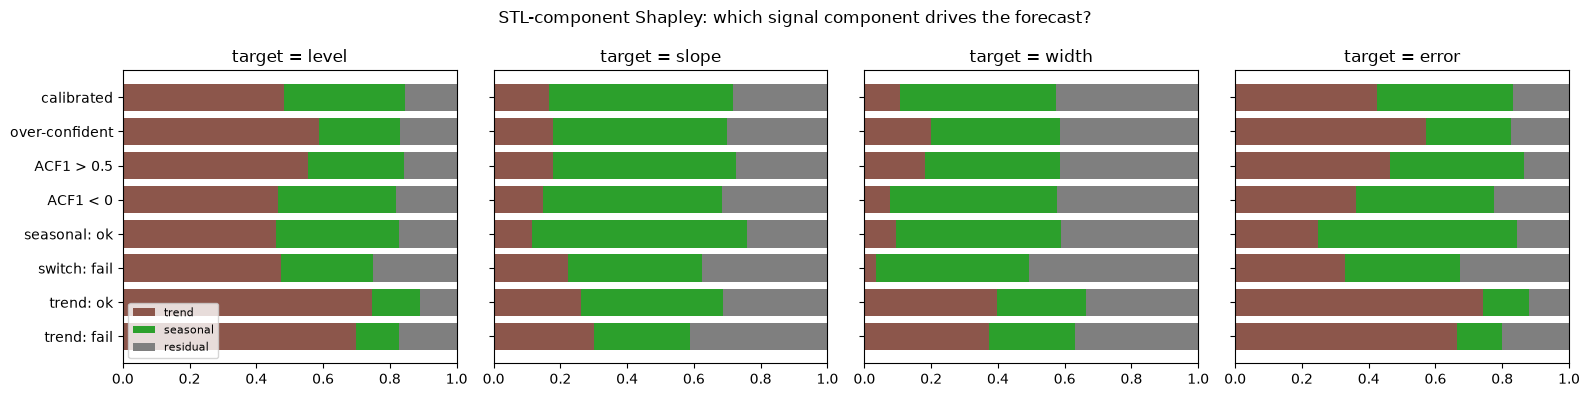

trend  seasonal  residual  energy_trend  energy_seasonal  energy_residual
contrast side target                                                                           
acf      fail error    0.36      0.41      0.22          0.18             0.37             0.45
              level    0.47      0.35      0.18          0.18             0.37             0.45
              slope    0.15      0.54      0.32          0.18             0.37             0.45
              width    0.08      0.50      0.42          0.18             0.37             0.45
         ok   error    0.46      0.40      0.13          0.39             0.41             0.21
              level    0.55      0.29      0.16          0.39             0.41             0.21
              slope    0.18      0.55      0.27          0.39             0.41             0.21
              width    0.18      0.41      0.41          0.39             0.41             0.21
calib    fail error    0.57      0.25      0.18          0.43             0.29             0.28
              level    0.59      0.24      0.17          0.43             0.29             0.28
              slope    0.18      0.52      0.30          0.43             0.29             0.28
              width    0.20      0.38      0.41          0.43             0.29             0.28
         ok   error    0.42      0.41      0.17          0.25             0.40             0.35
              level    0.48      0.36      0.15          0.25             0.40             0.35
              slope    0.17      0.55      0.28          0.25             0.40             0.35
              width    0.11      0.47      0.43          0.25             0.40             0.35
switch   fail error    0.33      0.34      0.33          0.05             0.32             0.62
              level    0.47      0.27      0.25          0.05             0.32             0.62
              slope    0.22      0.40      0.38          0.05             0.32             0.62
              width    0.04      0.46      0.51          0.05             0.32             0.62
         ok   error    0.25      0.60      0.16          0.16             0.58             0.26
              level    0.46      0.37      0.17          0.16             0.58             0.26
              slope    0.11      0.64      0.24          0.16             0.58             0.26
              width    0.09      0.49      0.41          0.16             0.58             0.26
trend    fail error    0.66      0.14      0.20          0.75             0.09             0.16
              level    0.70      0.13      0.17          0.75             0.09             0.16
              slope    0.30      0.29      0.41          0.75             0.09             0.16
              width    0.37      0.26      0.37          0.75             0.09             0.16
         ok   error    0.74      0.14      0.12          0.76             0.09             0.15
              level    0.75      0.14      0.11          0.76             0.09             0.15
              slope    0.26      0.43      0.31          0.76             0.09             0.15
              width    0.40      0.26      0.34          0.76             0.09             0.15

In [34]:
stl = AN.stl_table(sample, attrs)
PL.stl_bars(stl)
plt.show()
stl.groupby(["contrast", "side", "target"])[
    [
        "trend",
        "seasonal",
        "residual",
        "energy_trend",
        "energy_seasonal",
        "energy_residual",
    ]
].mean().round(2)

In [35]:
# within-dataset comparison of the trend and residual shares
rows = []
for comp in ["trend", "seasonal", "residual"]:
    t = AN.within_dataset_test(
        stl.assign(method="stl").rename(columns={comp: "share"}), "share"
    )
    rows.append(t.assign(component=comp))
pd.concat(rows)[
    [
        "component",
        "contrast",
        "target",
        "n_datasets",
        "median_fail",
        "median_ok",
        "share_fail_higher",
        "p_wilcoxon",
    ]
].round(3)

,component,contrast,target,n_datasets,median_fail,median_ok,share_fail_higher,p_wilcoxon
0,trend,acf,error,10,0.314,0.575,0.400,0.375
1,trend,acf,level,10,0.450,0.653,0.200,0.049
2,trend,acf,slope,10,0.104,0.108,0.400,0.557
3,trend,acf,width,10,0.039,0.135,0.200,0.010
4,trend,calib,error,12,0.610,0.300,0.583,0.092
5,trend,calib,level,12,0.566,0.377,0.500,0.266
6,trend,calib,slope,12,0.132,0.077,0.667,0.092
7,trend,calib,width,12,0.066,0.060,0.500,0.519
8,trend,switch,error,5,0.142,0.036,0.600,0.625
9,trend,switch,level,5,0.253,0.360,0.400,0.625


## 7. H3 – Are failures a region of the representation space?

Representation = state of the last context token after each block (13 layers incl. input embedding), for the analysis sample plus
1 674 random background windows. All probes use **dataset-grouped cross-validation**, so they cannot succeed by recognising the dataset.

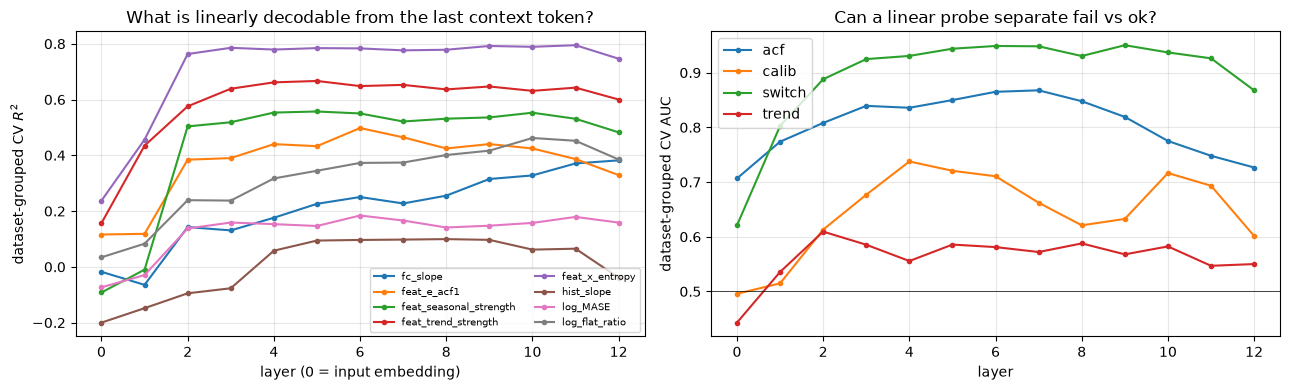

target,fc_slope,feat_e_acf1,feat_seasonal_strength,feat_trend_strength,feat_x_entropy,hist_slope,log_MASE,log_flat_ratio
layer,,,,,,,,
0,-0.02,0.12,-0.09,0.16,0.24,-0.46,-0.07,0.03
1,-0.06,0.12,-0.01,0.43,0.46,-0.15,-0.03,0.08
2,0.14,0.38,0.50,0.58,0.76,-0.09,0.14,0.24
3,0.13,0.39,0.52,0.64,0.79,-0.08,0.16,0.24
4,0.18,0.44,0.55,0.66,0.78,0.06,0.15,0.32
5,0.23,0.43,0.56,0.67,0.78,0.09,0.15,0.34
6,0.25,0.50,0.55,0.65,0.78,0.10,0.18,0.37
7,0.23,0.46,0.52,0.65,0.78,0.10,0.17,0.37
8,0.26,0.42,0.53,0.64,0.78,0.10,0.14,0.40


In [36]:
probes = (
    pd.read_parquet(P.CACHE_DIR / "probes.parquet")
    if (P.CACHE_DIR / "probes.parquet").exists()
    else R.linear_probes(rep["states"], table)
)
auc = (
    pd.read_parquet(P.CACHE_DIR / "contrast_auc.parquet")
    if (P.CACHE_DIR / "contrast_auc.parquet").exists()
    else R.contrast_probe_auc(rep["states"], table, sample)
)
PL.probe_curves(probes, auc)
plt.show()
probes.pivot(index="layer", columns="target", values="r2").round(2)

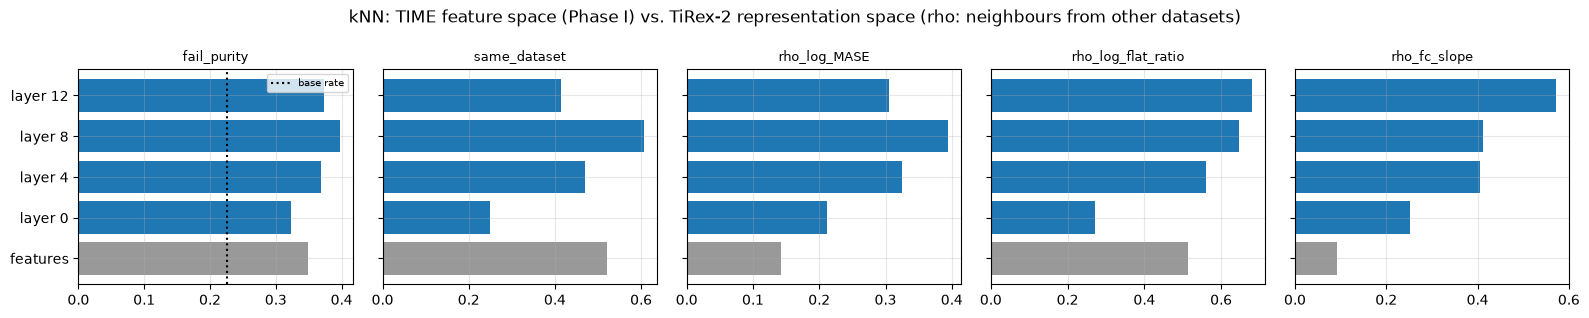

,space,fail_purity,fail_base_rate,same_dataset,rho_log_MASE,rho_log_flat_ratio,rho_fc_slope
0,features,0.348,0.225,0.520,0.142,0.512,0.091
1,layer 0,0.323,0.225,0.249,0.212,0.272,0.252
2,layer 4,0.368,0.225,0.469,0.324,0.562,0.405
3,layer 8,0.397,0.225,0.607,0.394,0.645,0.412
4,layer 12,0.373,0.225,0.414,0.305,0.681,0.573


In [37]:
knn = (
    pd.read_parquet(P.CACHE_DIR / "knn.parquet")
    if (P.CACHE_DIR / "knn.parquet").exists()
    else R.knn_report(rep["states"], table)
)
PL.knn_plot(knn)
plt.show()
knn.round(3)

In [38]:
# "information present but not used?" - out-of-fold probe for the historical slope at the last layer vs. the forecast slope
pred = R.probe_predictions(rep["states"], table, "hist_slope", 12)
t = table.assign(hist_slope_probe=pred)
grp = sample.drop_duplicates(["uid", "group"])[["uid", "group"]].merge(t, on="uid")
grp.groupby("group")[
    ["hist_slope", "hist_slope_probe", "fc_slope", "truth_slope"]
].median().round(3)

KeyError: 'group'

### Interactive explorer
Slider = layer, dropdown = colour; large dots = analysis sample, small dots = background. Click a point to see its forecast and
attribution strip.

In [ ]:
maps = R.layer_maps(rep["states"])
PL.representation_explorer(table, rep, maps, sample)

In [ ]:
# static version of the map for the report: layer 0, 6, 12 coloured by log MASE and by group
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
groups_of = sample.groupby("uid")["group"].first()
g = table.uid.map(groups_of).fillna("background")
for j, layer in enumerate([0, 6, 12]):
    m = maps[layer]
    axes[0, j].scatter(
        m[:, 0], m[:, 1], c=np.log10(table.MASE.clip(1e-2, 1e2)), s=4, cmap="viridis"
    )
    axes[0, j].set_title(f"layer {layer} – colour: log10 MASE")
    axes[1, j].scatter(m[:, 0], m[:, 1], c="lightgrey", s=3)
    for name, col in [
        ("trend_fail", "#d62728"),
        ("trend_ok", "#1f77b4"),
        ("switch_fail", "#ff7f0e"),
        ("season_ok", "#2ca02c"),
        ("overconf", "#9467bd"),
    ]:
        k = (g == name).to_numpy()
        axes[1, j].scatter(m[k, 0], m[k, 1], s=8, color=col, label=PL.LABELS[name])
    axes[1, j].set_title(f"layer {layer} – behaviour groups")
axes[1, 0].legend(fontsize=7)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
fig.savefig(PL.FIG_DIR / "layer_maps.png", dpi=130)
plt.show()

## 8. H4 – Counterfactual tests

In [ ]:
cf = C.trend_passthrough(sample)
PL.passthrough_plot(cf)
plt.show()
beta = C.passthrough_beta(cf)
beta.groupby(["mode", "tta_diff", "group"])[["beta", "flag_share"]].median().round(
    2
).unstack("group")

In [ ]:
lv = C.level_shift(sample)
PL.level_shift_plot(lv)
plt.show()

In [ ]:
ar = C.ar_residual_experiment()
PL.ar_plot(ar)
plt.show()

## 9. Synthesis

(filled in after all results are available)